# 08 - Modelo ML

## Preparar el entorno

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

## Mejorar la visualización

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
sns.set_style("whitegrid")

## Establecer las rutas

In [4]:
RAIZ = Path.cwd().resolve()
for carpeta in [RAIZ, *RAIZ.parents]:
    if (carpeta / 'requirements.txt').is_file() and (carpeta / 'data').is_dir():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError('Abra el notebook desde el proyecto.')

BASE = RAIZ / 'data/processed/ml/base_ml_08_1_knn.parquet'
REPORTS = RAIZ / 'data/reports/08_modelo_ml'
MODELOS = RAIZ / 'data/processed/ml/modelos'
for carpeta in [REPORTS, MODELOS]:
    carpeta.mkdir(parents = True, exist_ok = True)

def guardar_figura(nombre):
    plt.savefig(REPORTS / (nombre + '.png'), dpi = 150, bbox_inches = 'tight')

## Cargar los datos y construir la variable objetivo

In [5]:
predictores = [
    'pib_ppa_constante_2021', 'poblacion_total', 'va_industrial_constante_2015_usd',
    'ied_entrada_pct_pib', 'acceso_electricidad_pct', 'wgi_estabilidad_politica',
    'importaciones_producto_total_usd', 'proveedores_ex_col',
    'precio_petroleo_brent_usd_barril', 'precio_cafe_arabica_usd_kg',
    'participacion_oferta_col', 'va_sector_col_usd', 'ci_sector_col_usd',
    'eleccion_presidencial_col', 'trm_usd_por_cop'
]
claves = ['hs6', 'iso3_d', 'year']
base_ml = pd.read_parquet(BASE, columns = [*claves, 'nombre_producto_hs6_baci',
    'nombre_pais_destino', *predictores, 'brecha_relativa', 'trade_value_usd', 'exportaciones_estimadas_usd'])
base_ml.sort_values(claves, inplace = True)
assert not base_ml.duplicated(claves).any()
assert base_ml['brecha_relativa'].notna().all()
# Se calcula el año siguiente antes de seleccionar las brechas positivas.
siguiente = base_ml.groupby(['hs6', 'iso3_d'])[
    ['year', 'brecha_relativa', 'trade_value_usd', 'exportaciones_estimadas_usd']].shift(-1)
df = base_ml.assign(anio_siguiente = siguiente['year'], brecha_siguiente = siguiente['brecha_relativa'],
    comercio_siguiente = siguiente['trade_value_usd'], estimado_siguiente = siguiente['exportaciones_estimadas_usd'])
df = df.loc[df['anio_siguiente'].eq(df['year'] + 1) & df['brecha_relativa'].gt(0)].copy()
df['Reduce_brecha'] = ((df['brecha_siguiente'] < df['brecha_relativa'])
    & df['comercio_siguiente'].gt(0) & df['estimado_siguiente'].gt(0)).astype('int8')
df = df[[*claves, 'nombre_producto_hs6_baci', 'nombre_pais_destino', *predictores,
    'brecha_relativa', 'anio_siguiente', 'brecha_siguiente', 'comercio_siguiente',
    'estimado_siguiente', 'Reduce_brecha']].sort_values(['year', 'iso3_d', 'hs6']).reset_index(drop = True)
print('Dimensiones del dataset de clasificación:', df.shape)
print('Años de condiciones:', sorted(df['year'].unique()))
print('Años de resultado:', sorted(df['anio_siguiente'].astype(int).unique()))
display(df.head(3))
print("Distribución de la variable objetivo 'Reduce_brecha':")
display(df['Reduce_brecha'].value_counts(normalize = True).rename('proporcion').to_frame())

Dimensiones del dataset de clasificación: (618208, 26)
Años de condiciones: [np.int16(2017), np.int16(2018), np.int16(2019), np.int16(2020), np.int16(2021), np.int16(2022), np.int16(2023)]
Años de resultado: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Distribución de la variable objetivo 'Reduce_brecha':


,hs6,iso3_d,year,nombre_producto_hs6_baci,nombre_pais_destino,pib_ppa_constante_2021,poblacion_total,va_industrial_constante_2015_usd,ied_entrada_pct_pib,acceso_electricidad_pct,wgi_estabilidad_politica,importaciones_producto_total_usd,proveedores_ex_col,precio_petroleo_brent_usd_barril,precio_cafe_arabica_usd_kg,participacion_oferta_col,va_sector_col_usd,ci_sector_col_usd,eleccion_presidencial_col,trm_usd_por_cop,brecha_relativa,anio_siguiente,brecha_siguiente,comercio_siguiente,estimado_siguiente,Reduce_brecha
0,010121,ABW,2017,"Horses: live, pure-bred breeding animals",Aruba,"4,155,122,005.38","108,735.00","414,525,108.60",5.25,100.00,1.22,0.00,0,54.40,3.32,0.00,"4,961,836,144.02","5,473,645,186.81",0,0.00,1.00,"2,018.00",1.00,0.00,"1,214.99",0
1,010129,ABW,2017,"Horses: live, other than pure-bred breeding an...",Aruba,"4,155,122,005.38","108,735.00","414,525,108.60",5.25,100.00,1.22,0.00,0,54.40,3.32,0.00,"4,961,836,144.02","5,473,645,186.81",0,0.00,1.00,"2,018.00",1.00,0.00,122.05,0
2,010190,ABW,2017,Mules and hinnies: live,Aruba,"4,155,122,005.38","108,735.00","414,525,108.60",5.25,100.00,1.22,0.00,0,54.40,3.32,0.00,"4,961,836,144.02","5,473,645,186.81",0,0.00,1.00,"2,018.00",0.00,0.00,0.00,0


,proporcion
Reduce_brecha,
0,0.70
1,0.30


## Preprocesar y dividir entrenamiento y prueba

In [6]:
X = df[predictores].astype('float32')
y = df['Reduce_brecha']
# Se conserva la partición aleatoria estratificada del antiguo 09.
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size = .2, random_state = 42, stratify = y)
indices_train, indices_test = X_train.index.to_numpy(), X_test.index.to_numpy()
print('Forma de X_train original:', X_train.shape)
print('Forma de X_test original:', X_test.shape)
# Los quince predictores son numéricos; los árboles no necesitan escalado ni codificación.
X_train, X_test = X_train.to_numpy(), X_test.to_numpy()
print('Forma de X_train procesado:', X_train.shape)
print('Forma de X_test procesado:', X_test.shape)
assert X_train.shape[1] == X_test.shape[1] == 15
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
print('Alcance: ejercicio retrospectivo con la preparación histórica existente.')

Forma de X_train original: (494566, 15)
Forma de X_test original: (123642, 15)
Forma de X_train procesado: (494566, 15)
Forma de X_test procesado: (123642, 15)
Alcance: ejercicio retrospectivo con la preparación histórica existente.


## Entrenar el Árbol de Decisión

Evaluación del Árbol de Decisión:
Accuracy: 0.677
              precision    recall  f1-score   support

           0       0.73      0.85      0.79     86604
           1       0.44      0.28      0.34     37038

    accuracy                           0.68    123642
   macro avg       0.59      0.56      0.56    123642
weighted avg       0.65      0.68      0.65    123642



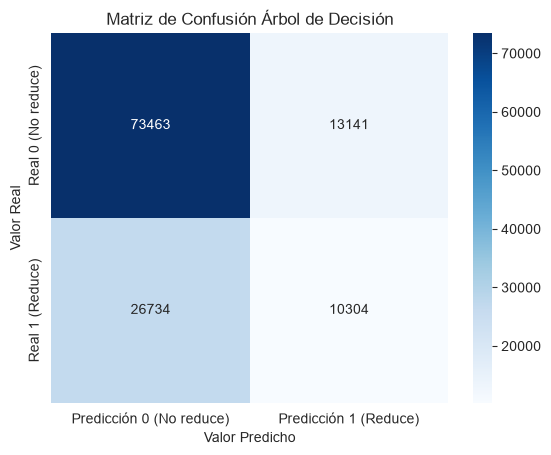

In [7]:
# Inicializar y entrenar el Árbol de Decisión: parámetros de clase
tree_model = DecisionTreeClassifier(random_state=42, max_depth=20)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

cm_tree = confusion_matrix(y_test, y_pred_tree)
plt.figure()
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicción 0 (No reduce)', 'Predicción 1 (Reduce)'],
    yticklabels=['Real 0 (No reduce)', 'Real 1 (Reduce)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión Árbol de Decisión')
guardar_figura('matriz_arbol')
plt.show()

print('Evaluación del Árbol de Decisión:')
print(f'Accuracy: {accuracy_score(y_test, y_pred_tree):.3f}')
print(classification_report(y_test, y_pred_tree, zero_division=0))

## Entrenar Random Forest

Evaluación del Random Forest:
Accuracy: 0.714
              precision    recall  f1-score   support

           0       0.73      0.94      0.82     86604
           1       0.57      0.19      0.29     37038

    accuracy                           0.71    123642
   macro avg       0.65      0.56      0.55    123642
weighted avg       0.68      0.71      0.66    123642



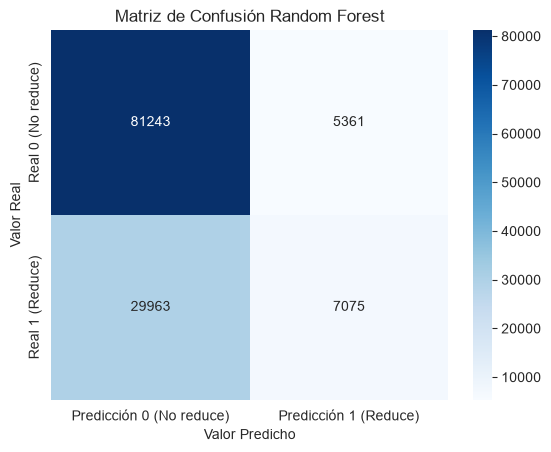

In [8]:
# Inicializar y entrenar el Random Forest: parámetros de clase
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, max_depth=20, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure()
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicción 0 (No reduce)', 'Predicción 1 (Reduce)'],
    yticklabels=['Real 0 (No reduce)', 'Real 1 (Reduce)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión Random Forest')
guardar_figura('matriz_random_forest')
plt.show()

print('Evaluación del Random Forest:')
print(f'Accuracy: {accuracy_score(y_test, y_pred_rf):.3f}')
print(classification_report(y_test, y_pred_rf, zero_division=0))

## Entrenar Gradient Boosting

Evaluación de Gradient Boosting:
Accuracy: 0.703
              precision    recall  f1-score   support

           0       0.71      0.99      0.82     86604
           1       0.57      0.04      0.07     37038

    accuracy                           0.70    123642
   macro avg       0.64      0.51      0.45    123642
weighted avg       0.66      0.70      0.60    123642



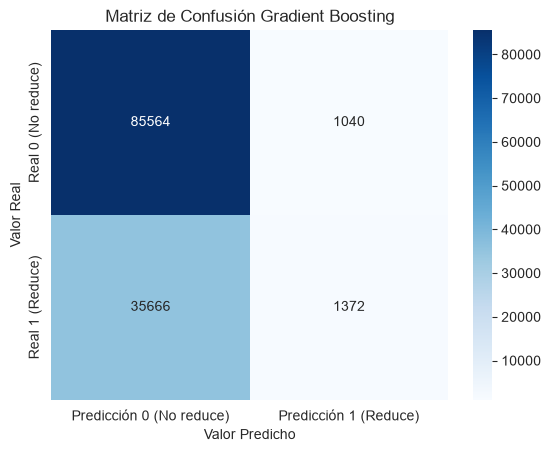

In [9]:
# Inicializar y entrenar Gradient Boosting: parámetros de clase
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure()
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicción 0 (No reduce)', 'Predicción 1 (Reduce)'],
    yticklabels=['Real 0 (No reduce)', 'Real 1 (Reduce)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión Gradient Boosting')
guardar_figura('matriz_gradient_boosting')
plt.show()

print('Evaluación de Gradient Boosting:')
print(f'Accuracy: {accuracy_score(y_test, y_pred_gb):.3f}')
print(classification_report(y_test, y_pred_gb, zero_division=0))

## Comparar las curvas ROC

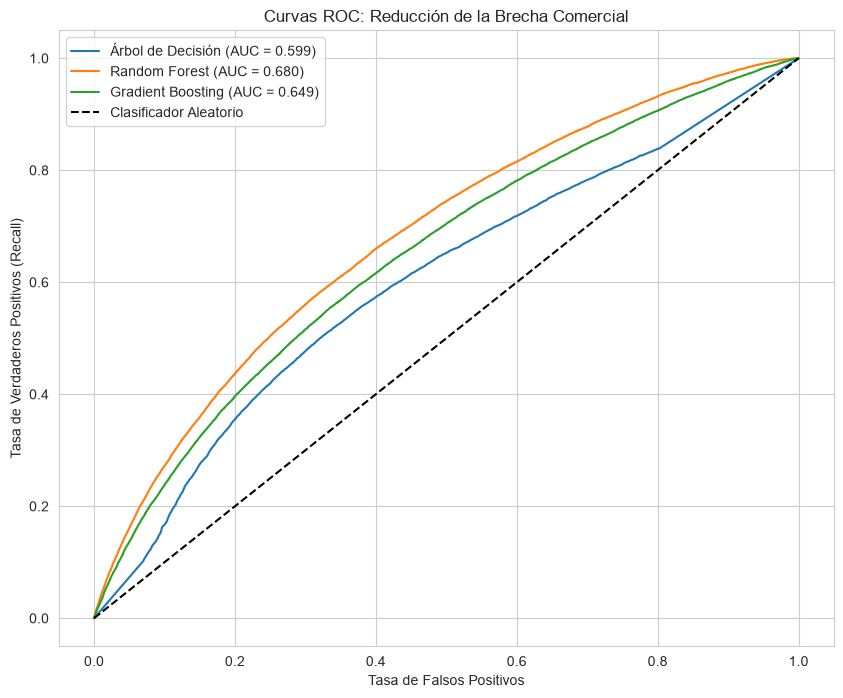

In [10]:
# Probabilidades para la clase positiva: reducción de la brecha
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
auc_tree = auc(fpr_tree, tpr_tree)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)
auc_gb = auc(fpr_gb, tpr_gb)

plt.figure(figsize=(10, 8))
plt.plot(fpr_tree, tpr_tree, label=f'Árbol de Decisión (AUC = {auc_tree:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curvas ROC: Reducción de la Brecha Comercial')
plt.legend()
guardar_figura('curvas_roc')
plt.show()

## Comparar las métricas de los tres modelos

In [11]:
# Tabla de resultados, sin seleccionar todavía un ganador
resultados = []
for nombre, prediccion, valor_auc in [
    ('Árbol de Decisión', y_pred_tree, auc_tree),
    ('Random Forest', y_pred_rf, auc_rf),
    ('Gradient Boosting', y_pred_gb, auc_gb)
]:
    reporte = classification_report(y_test, prediccion, output_dict=True, zero_division=0)
    resultados.append({'Modelo':nombre, 'Accuracy':accuracy_score(y_test, prediccion),
        'Precision_1':reporte['1']['precision'], 'Recall_1':reporte['1']['recall'],
        'F1_1':reporte['1']['f1-score'], 'AUC':valor_auc})
comparacion = pd.DataFrame(resultados)
display(comparacion)

,Modelo,Accuracy,Precision_1,Recall_1,F1_1,AUC
0,Árbol de Decisión,0.68,0.44,0.28,0.34,0.60
1,Random Forest,0.71,0.57,0.19,0.29,0.68
2,Gradient Boosting,0.70,0.57,0.04,0.07,0.65


## Guardar los modelos y los resultados

In [12]:
comparacion.to_csv(REPORTS / 'metricas_modelos.csv', index = False)
joblib.dump({'rf_model': rf_model,
    'predictores': predictores, 'tipo_numerico': 'float32'}, MODELOS / 'random_forest.joblib', compress = 3)
predicciones = df.loc[indices_test, [*claves, 'nombre_producto_hs6_baci',
    'nombre_pais_destino', 'anio_siguiente', 'Reduce_brecha']].reset_index(drop = True)
for nombre, predicho, probabilidad in [('arbol', y_pred_tree, y_prob_tree),
    ('rf', y_pred_rf, y_prob_rf), ('gb', y_pred_gb, y_prob_gb)]:
    predicciones['pred_' + nombre] = predicho
    predicciones['prob_' + nombre] = probabilidad
predicciones.to_parquet(MODELOS / 'predicciones_prueba.parquet', index = False)
print('Modelos guardados en:', MODELOS.relative_to(RAIZ))
print('Predicciones de prueba:', len(predicciones))

Modelos guardados en: data\processed\ml\modelos
Predicciones de prueba: 123642


## Seleccionar Random Forest

In [13]:
mejor_auc = comparacion.loc[comparacion['AUC'].idxmax()]
print('Mayor AUC observado:', mejor_auc['Modelo'], '-', round(mejor_auc['AUC'], 4))
print('Modelo seleccionado para el ajuste de umbral y SHAP: Random Forest.')

Mayor AUC observado: Random Forest - 0.6804
Modelo seleccionado para el ajuste de umbral y SHAP: Random Forest.


## Ajustar el umbral con calibración

In [14]:
# La reserva de prueba se divide como en el antiguo análisis: mitad calibración y mitad evaluación.
cal, eva = train_test_split(np.arange(len(y_test)), test_size = .5,
    random_state = 42, stratify = y_test)
calibracion = predicciones.iloc[cal].reset_index(drop = True)
evaluacion = predicciones.iloc[eva].reset_index(drop = True)
assert set(cal).isdisjoint(eva)
meta_recall = .80
fpr_cal, recall_cal, umbrales = roc_curve(calibracion['Reduce_brecha'], calibracion['prob_rf'],
    drop_intermediate = False)
umbral_rf = float(umbrales[np.isfinite(umbrales) & (recall_cal >= meta_recall)].max())
print(f'Umbral RF elegido solo con calibración: {umbral_rf:.6f}')
print(f'Meta de recall en calibración: {meta_recall:.0%}')

resultados_umbral = []
for nombre, tabla in [('Calibración', calibracion), ('Evaluación', evaluacion)]:
    for corte in [.5, umbral_rf]:
        predicho = (tabla['prob_rf'] >= corte).astype('int8')
        reporte = classification_report(tabla['Reduce_brecha'], predicho, output_dict = True, zero_division = 0)
        tn, fp, fn, tp = confusion_matrix(tabla['Reduce_brecha'], predicho).ravel()
        resultados_umbral.append({'Partición': nombre, 'Umbral': corte,
            'Precision_1': reporte['1']['precision'], 'Recall_1': reporte['1']['recall'],
            'F1_1': reporte['1']['f1-score'], 'FP': fp, 'FN': fn})
comparacion_umbral = pd.DataFrame(resultados_umbral)
display(comparacion_umbral)
evaluacion['pred_rf_ajustada'] = (evaluacion['prob_rf'] >= umbral_rf).astype('int8')
print('Random Forest - evaluación con umbral ajustado:')
print(classification_report(evaluacion['Reduce_brecha'], evaluacion['pred_rf_ajustada'], zero_division = 0))
comparacion_umbral.to_csv(REPORTS / 'comparacion_umbral.csv', index = False)

Umbral RF elegido solo con calibración: 0.233094
Meta de recall en calibración: 80%
Random Forest - evaluación con umbral ajustado:
              precision    recall  f1-score   support

           0       0.83      0.42      0.56     43302
           1       0.37      0.80      0.51     18519

    accuracy                           0.53     61821
   macro avg       0.60      0.61      0.53     61821
weighted avg       0.69      0.53      0.54     61821



,Partición,Umbral,Precision_1,Recall_1,F1_1,FP,FN
0,Calibración,0.50,0.57,0.20,0.29,2705,14885
1,Calibración,0.23,0.37,0.80,0.51,24883,3703
2,Evaluación,0.50,0.56,0.19,0.28,2656,15078
3,Evaluación,0.23,0.37,0.80,0.51,25121,3679


## Comparar las matrices antes y después del ajuste

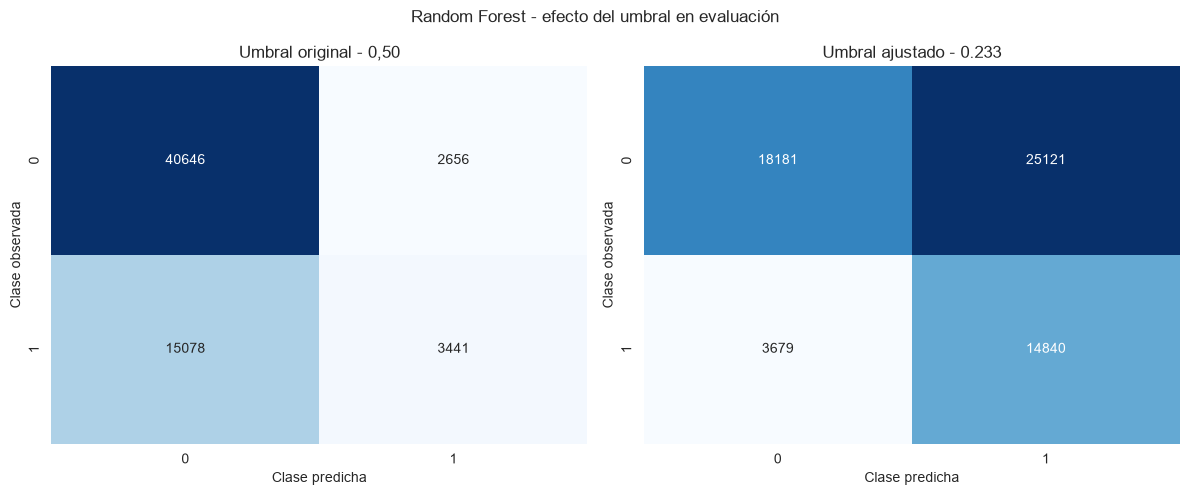

In [15]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))
for ax, predicho, titulo in [(axes[0], evaluacion['pred_rf'], 'Umbral original - 0,50'),
    (axes[1], evaluacion['pred_rf_ajustada'], f'Umbral ajustado - {umbral_rf:.3f}')]:
    sns.heatmap(confusion_matrix(evaluacion['Reduce_brecha'], predicho), annot = True,
        fmt = 'd', cmap = 'Blues', ax = ax, cbar = False)
    ax.set(title = titulo, xlabel = 'Clase predicha', ylabel = 'Clase observada')
fig.suptitle('Random Forest - efecto del umbral en evaluación')
fig.tight_layout()
guardar_figura('confusion_umbral_rf')
plt.show()

## Calcular las contribuciones SHAP

In [16]:
# Mismo procedimiento del análisis anterior: 100 casos de evaluación y semilla 42.
posiciones_shap = np.sort(np.random.default_rng(42).choice(len(evaluacion), size = 100, replace = False))
X_shap = X_test[eva][posiciones_shap]
casos_shap = evaluacion.iloc[posiciones_shap].reset_index(drop = True)
explainer = shap.TreeExplainer(rf_model)
valores_todas_clases = explainer.shap_values(X_shap)
clase_uno = int(np.flatnonzero(rf_model.classes_ == 1)[0])
valores_shap = valores_todas_clases[:, :, clase_uno]
valor_base = float(explainer.expected_value[clase_uno])
np.testing.assert_allclose(valor_base + valores_shap.sum(axis = 1), casos_shap['prob_rf'],
    rtol = 1e-5, atol = 1e-6)
nombres_grafico = ['PIB PPA', 'Población', 'VA industrial destino', 'IED recibida',
    'Electricidad', 'Estabilidad política', 'Importaciones HS6', 'Proveedores sin Colombia',
    'Petróleo Brent', 'Café arábica', 'Oferta colombiana', 'VA sector Colombia',
    'CI sector Colombia', 'Elección presidencial', 'TRM USD/COP']
X_shap_grafico = pd.DataFrame(X_shap, columns = nombres_grafico)
importancia_shap = pd.DataFrame({'Variable': predictores, 'Etiqueta': nombres_grafico,
    'SHAP_absoluto_medio': np.abs(valores_shap).mean(axis = 0)}).sort_values('SHAP_absoluto_medio', ascending = False)
importancia_shap.to_csv(REPORTS / 'importancia_shap.csv', index = False)
np.savez_compressed(REPORTS / 'valores_shap.npz', valores = valores_shap, valor_base = valor_base, X = X_shap)
casos_shap.to_parquet(REPORTS / 'casos_shap.parquet', index = False)
print('Suma SHAP + valor base = probabilidad RF: comprobada.')

Suma SHAP + valor base = probabilidad RF: comprobada.


## Graficar la relevancia global SHAP

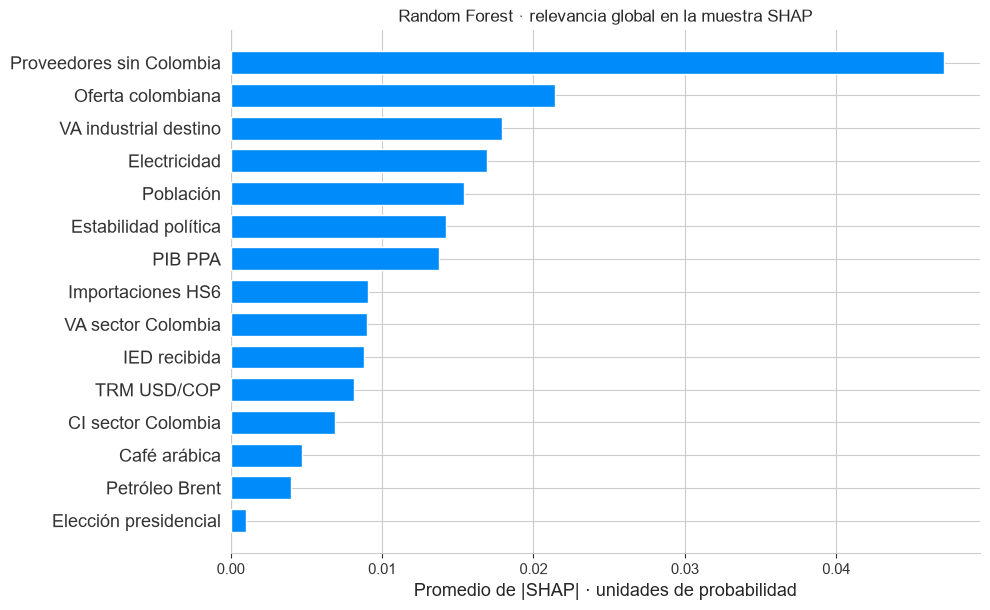

In [17]:
shap.summary_plot(valores_shap, X_shap_grafico, plot_type = 'bar', max_display = 15,
    show = False, plot_size = (10, 6))
plt.title('Random Forest · relevancia global en la muestra SHAP')
plt.xlabel('Promedio de |SHAP| · unidades de probabilidad')
guardar_figura('shap_global')
plt.show()

## Graficar la dirección de las contribuciones SHAP

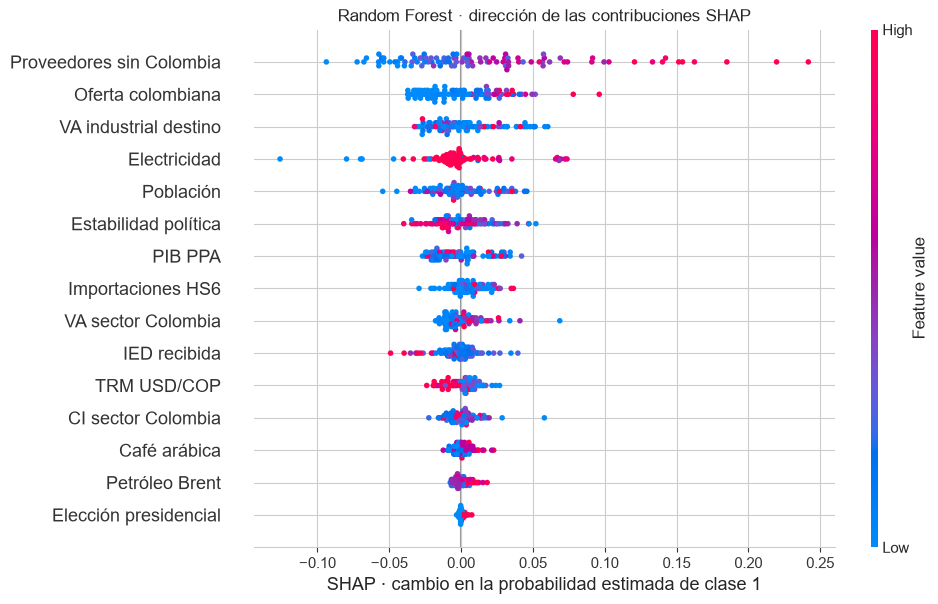

In [18]:
shap.summary_plot(valores_shap, X_shap_grafico, max_display = 15,
    show = False, plot_size = (10, 6), rng = 42)
plt.title('Random Forest · dirección de las contribuciones SHAP')
plt.xlabel('SHAP · cambio en la probabilidad estimada de clase 1')
guardar_figura('shap_direccion')
plt.show()